# テキストデータの取り扱い、線型近似、非線型近似

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
%matplotlib inline

In [2]:
plt.style.use("ggplot")

In [3]:
df = pd.read_csv("sensor_data.txt", delimiter="\t", header=6)

In [4]:
df.head()

,Time[s],Intensity[a.u.]
0,[1],11.817864
1,[2],11.797914
2,[3],11.797964
3,[4],11.778014
4,[5],11.818065


In [5]:
df["Time[s]"] = df["Time[s]"].apply(lambda x: float(x[1:-1]))

In [6]:
df.head()

,Time[s],Intensity[a.u.]
0,1.0,11.817864
1,2.0,11.797914
2,3.0,11.797964
3,4.0,11.778014
4,5.0,11.818065


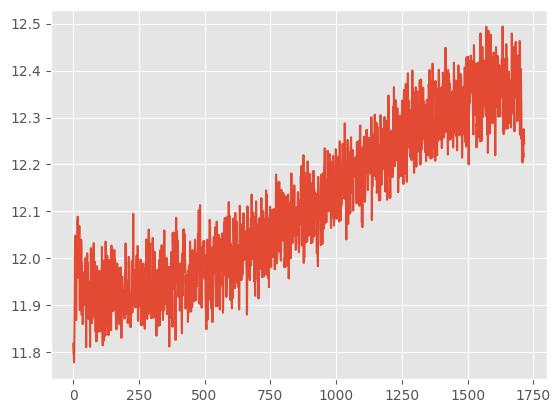

In [7]:
plt.plot(df["Time[s]"], df["Intensity[a.u.]"])

In [8]:
data = df["Intensity[a.u.]"][:250]

In [9]:
data

0      11.817864
1      11.797914
2      11.797964
3      11.778014
4      11.818065
         ...    
245    12.026493
246    11.866602
247    11.956711
248    11.916821
249    11.956931
Name: Intensity[a.u.], Length: 250, dtype: float64

In [12]:
data.describe()

count    250.000000
mean      11.928999
std        0.057711
min       11.778014
25%       11.889238
50%       11.921094
75%       11.967363
max       12.094689
Name: Intensity[a.u.], dtype: float64

In [13]:
def linear_fit(x, a, b):
    return a * x + b

In [14]:
param, cov = curve_fit(linear_fit, df["Time[s]"], df["Intensity[a.u.]"])

In [15]:
param

array([3.10054862e-04, 1.18501781e+01])

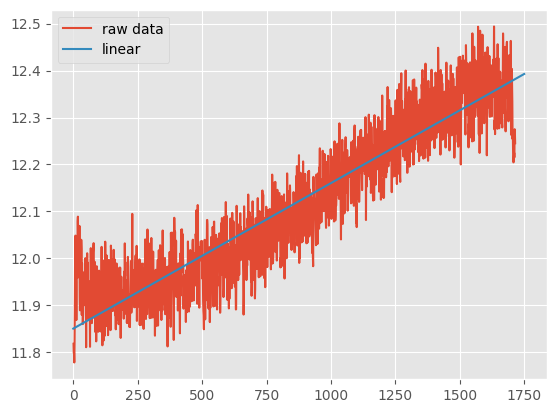

In [16]:
plt.plot(df["Time[s]"], df["Intensity[a.u.]"], label="raw data")
x = np.arange(0, 1750, 0.01)
y = param[0] * x + param[1]
plt.plot(x, y, label="linear")
plt.legend()


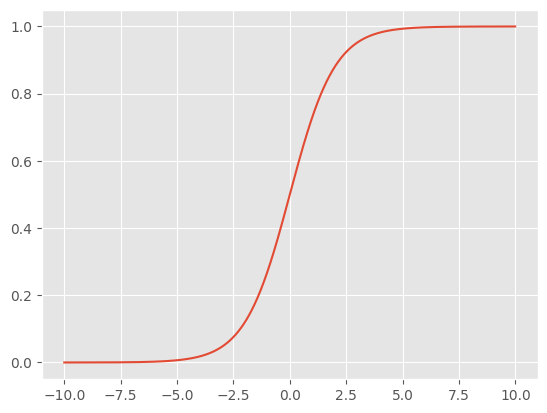

In [18]:
x = np.arange(-10, 10, 0.01)
y = 1.0 / (1.0 + np.exp(-x))
plt.plot(x, y)

In [19]:
def nonlinear_fit(x, a, b, c, d):
    return a / (1.0 + np.exp(-b*x+c)) + d

In [20]:
param2, cov2 = curve_fit(nonlinear_fit, df["Time[s]"], df["Intensity[a.u.]"])

/Users/unnosatsu/Library/Python/3.9/lib/python/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: overflow encountered in exp
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [21]:
param2

array([-4.84020862e-01, -3.82954502e-03, -3.85352591e+00,  1.23968891e+01])

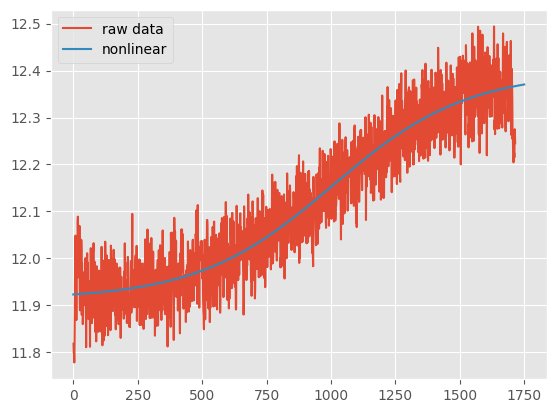

In [22]:
plt.plot(df["Time[s]"], df["Intensity[a.u.]"], label="raw data")
x = np.arange(0, 1750, 0.01)
y = nonlinear_fit(x, param2[0], param2[1], param2[2], param2[3])
plt.plot(x, y, label="nonlinear")
plt.legend()